<p style="text-align:center">
    <a href="https://www.ict.mahidol.ac.th/en/" target="_blank">
    <img src="https://www3.ict.mahidol.ac.th/ICTSurveysV2/Content/image/MUICT2.png" width="400" alt="Faculty of ICT">
    </a>
</p>

# ITGE275: Economics
## Session 7: Macroeconomic Health – GDP, Growth, and Inequality
**Topic:** Measuring the Economy: GDP, Business Cycles, and Income Inequality.

---
### 👦 Student Information 👧

**Your name:** Qimin Zhu  
**ID:** 6888143

---

### **1. Introduction: The Scorecard of Nations**

We have moved from Microeconomics (Individual Choices) to **Macroeconomics** (Aggregate Systems).

To manage a country's economy, we need metrics. The two most critical are:
1.  **GDP (Gross Domestic Product):** The total value of all goods and services produced. It measures the "Size" of the economic pie.
2.  **Gini Coefficient:** A measure of how that pie is shared (Inequality).

In this session, we will use Data Science techniques to:
* Decompose GDP into long-term **Trends** and short-term **Cycles** (Recessions).
* Calculate Inequality using the **Lorenz Curve**.

In [14]:
# Step 1: Import Libraries
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import integrate
import ipywidgets as widgets
from IPython.display import display

# Configure plotting style
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

print("Libraries loaded successfully.")

Libraries loaded successfully.


### **2. GDP Analysis: Trend vs. Cycle**

GDP grows over time (Trend), but it fluctuates around that trend (Business Cycle). 

$$ GDP_t = Trend_t + Cycle_t $$

* **Trend:** Long-term growth driven by technology and capital.
* **Cycle:** Booms (Positive) and Recessions (Negative).

We use the **Hodrick-Prescott (HP) Filter**, a standard macroeconomic algorithm, to separate these components.

We will use synthetic data mimicking Thailand's GDP history (1990-2023).

In [15]:
# === DATA GENERATION ===
years = pd.date_range(start='1990', end='2024', freq='YE')
n = len(years)

# 1. Create a Trend (Exponential Growth)
trend = 100 * np.exp(0.03 * np.arange(n)) # 3% annual growth base

# 2. Create Cycles (Shocks)
cycle = np.zeros(n)
# 1997 Tom Yam Kung Crisis
cycle[7:10] = [-15, -10, -5] 
# 2008 Global Financial Crisis
cycle[18:20] = [-8, -4]
# 2011 Floods
cycle[21] = -5
# 2020 COVID-19
cycle[30:33] = [-12, -6, -2]

# Add some random noise
noise = np.random.normal(0, 1, n)

# Total GDP
gdp_data = trend + cycle + noise

df_gdp = pd.DataFrame({'Year': years, 'Real_GDP': gdp_data})
df_gdp.set_index('Year', inplace=True)

print("Synthetic GDP Data Created (Base 100 in 1990)")
display(df_gdp.head())

Synthetic GDP Data Created (Base 100 in 1990)


,Real_GDP
Year,
1990-12-31,100.598635
1991-12-31,102.692532
1992-12-31,107.120879
1993-12-31,110.370909
1994-12-31,111.224552


### **3. The Hodrick-Prescott (HP) Filter**

The HP Filter minimizes the following function:
$$ \sum (y_t - \tau_t)^2 + \lambda \sum ((\tau_{t+1} - \tau_t) - (\tau_t - \tau_{t-1}))^2 $$

* $y_t$: Actual GDP.
* $\tau_t$: The Trend we want to find.
* $\lambda$: Smoothing parameter (usually 6.25 for annual data, 1600 for quarterly).

Let's apply it using `statsmodels`.

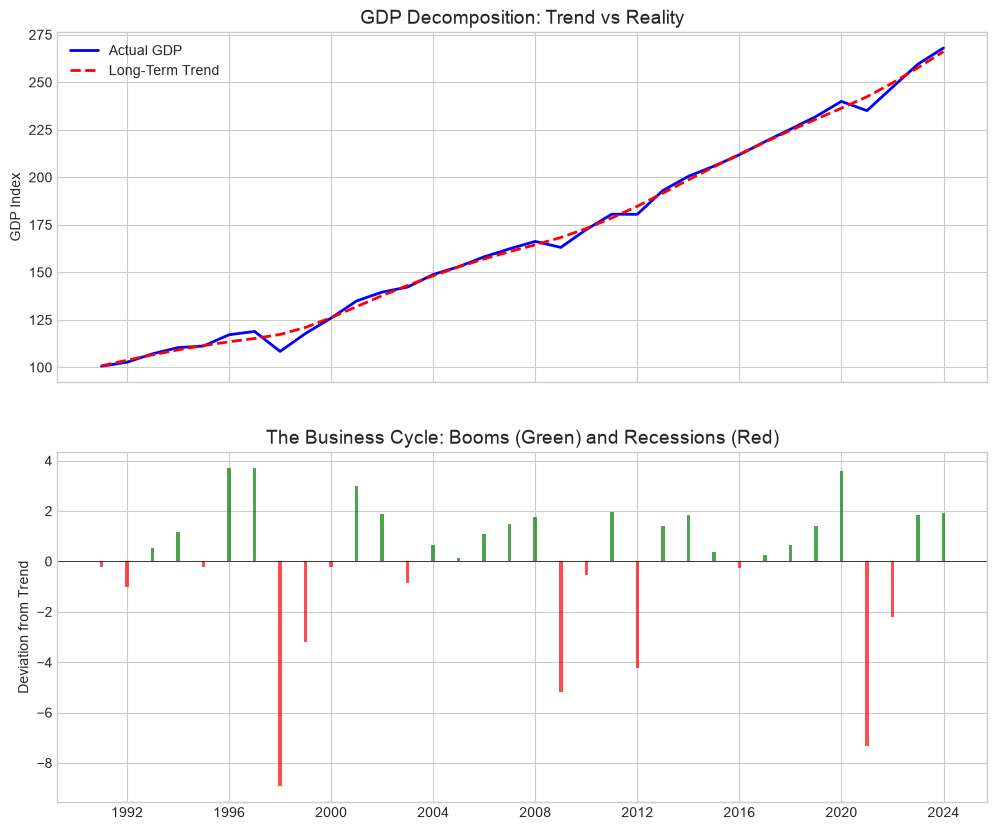

In [16]:
# Apply HP Filter
# lambda=6.25 is standard for annual data
cycle, trend = sm.tsa.filters.hpfilter(df_gdp['Real_GDP'], lamb=6.25)

df_gdp['Trend'] = trend
df_gdp['Cycle'] = cycle

# === VISUALIZATION ===
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

# Plot 1: Actual vs Trend
ax1.plot(df_gdp.index, df_gdp['Real_GDP'], label='Actual GDP', color='blue', linewidth=2)
ax1.plot(df_gdp.index, df_gdp['Trend'], label='Long-Term Trend', color='red', linestyle='--', linewidth=2)
ax1.set_title('GDP Decomposition: Trend vs Reality', fontsize=14)
ax1.set_ylabel('GDP Index')
ax1.legend()
ax1.grid(True)

# Plot 2: The Cycle (Deviation from Trend)
colors = ['red' if x < 0 else 'green' for x in df_gdp['Cycle']]
ax2.bar(df_gdp.index, df_gdp['Cycle'], color=colors, alpha=0.7, width=50)
ax2.axhline(0, color='black', linewidth=0.5)
ax2.set_title('The Business Cycle: Booms (Green) and Recessions (Red)', fontsize=14)
ax2.set_ylabel('Deviation from Trend')

plt.show()

### **4. Measuring Inequality: The Lorenz Curve**

High GDP does not mean everyone is rich. We need to check distribution.

**The Lorenz Curve** plots cumulative share of population vs. cumulative share of income.
* **Line of Equality (45-degree):** The bottom 20% own 20% of wealth.
* **Lorenz Curve:** The bottom 20% might own only 5% of wealth.

**Gini Coefficient:** The area between the Equality Line and the Lorenz Curve. (0 = Perfect Equality, 1 = Perfect Inequality).

In [17]:
def plot_inequality(scenario):
    # Define Income Distributions by Decile (10 groups, 10% each)
    # Values represent the % of total national income held by that decile
    
    if scenario == 'Perfect Equality':
        income_shares = np.array([10, 10, 10, 10, 10, 10, 10, 10, 10, 10])
    elif scenario == 'Scandinavia (Low Inequality)':
        income_shares = np.array([4, 5, 6, 7, 8, 9, 10, 12, 15, 24])
    elif scenario == 'Emerging Economy (High Inequality)':
        income_shares = np.array([1, 2, 3, 4, 5, 7, 9, 12, 17, 40])
    elif scenario == 'Extreme Oligarchy':
        income_shares = np.array([0, 0, 0, 1, 1, 2, 3, 5, 8, 80])
        
    # Calculate Cumulative Shares
    # Add 0 at the start for the plot origin (0,0)
    cum_income = np.cumsum(income_shares)
    cum_income = np.insert(cum_income, 0, 0) / 100.0
    
    cum_population = np.linspace(0, 1, 11)
    
    # Calculate Gini Coefficient
    # Area under Lorenz Curve (B)
    area_B = integrate.trapezoid(cum_income, cum_population)
    # Area under Equality Line = 0.5
    # Gini = (0.5 - B) / 0.5 = 1 - 2B
    gini = 1 - 2 * area_B
    
    # Plotting
    fig, ax = plt.subplots(figsize=(8, 8))
    
    # Equality Line
    ax.plot([0, 1], [0, 1], linestyle='--', color='black', label='Line of Perfect Equality')
    
    # Lorenz Curve
    ax.plot(cum_population, cum_income, marker='o', color='purple', label=f'Lorenz Curve ({scenario})')
    ax.fill_between(cum_population, cum_population, cum_income, color='purple', alpha=0.2, label='Inequality Gap')
    
    ax.set_title(f'Lorenz Curve Analysis\nGini Coefficient: {gini:.3f}', fontsize=14)
    ax.set_xlabel('Cumulative Share of Population (Poorest -> Richest)')
    ax.set_ylabel('Cumulative Share of Income')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.legend()
    ax.grid(True)
    plt.show()

# Interactive Widget
widgets.interactive(plot_inequality, 
    scenario=['Perfect Equality', 'Scandinavia (Low Inequality)', 
              'Emerging Economy (High Inequality)', 'Extreme Oligarchy']
)

interactive(children=(Dropdown(description='scenario', options=('Perfect Equality', 'Scandinavia (Low Inequali…

---
## **5. Homework Assignment**

**Objective:** Analyze macroeconomic health indicators.

#### **Question 1: Diagnosing Recessions**
Look at the "Business Cycle" bar chart (Red/Green bars) generated in Section 3.
1.  Identify the years where the Cycle component drops below **-10**.
2.  Correlate these drops with real-world economic history. What happened in **1997-1998** and **2020**?
3.  Why is the "Trend" line smoother than the "Actual GDP" line?

#### **Question 2: Growth vs. Inequality**
Imagine a country has:
* **GDP Growth:** +10% per year (Very High).
* **Gini Coefficient:** Rising from 0.30 to 0.55.

**Task:** Explain what this implies for the "Average Citizen" vs. the "Median Citizen." Does the GDP growth accurately reflect the life of the majority?

*(Write your answers in the Markdown cell below)*

### **Student Answers Space**

**Q1 Analysis:**
1. There's no year below -10, the lowest is 1998 around -9.
2. There might have been a crisis in 1998, which explains the boost of 1997. In 2020, the globle spread of covid-19 causes a dramatic decline.

**Q2 Analysis:**
1. The high GDP Growth could improve the economy in terms of income and the number of jobs. Therefore, the income of Average Citizen may increase, but the Median Citizen might experience a slower improvement because the rising Gini coefficient indicates increasing income inequality.